# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

np.random.seed(1)


NumPy version: 2.4.6
Pandas version: 2.2.3


In [2]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [3]:
S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

z = S @ theta + bias
print("z =", z)
assert np.isclose(z[0], 6.3)

probabilities = 1 / (1 + np.exp(-z))
print("probabilities =", probabilities.round(4))
predicted_spam = probabilities >= 0.5
print("predicted_spam =", predicted_spam)
print("Spam e-mail indices:", np.where(predicted_spam)[0])


z = [6.3 1.8 4.7 2.2]
probabilities = [0.9982 0.8581 0.991  0.9002]
predicted_spam = [ True  True  True  True]
Spam e-mail indices: [0 1 2 3]


In [4]:
# Auto-graded cell (S)
# Skip it

In [5]:
# Auto-graded cell (theta)
# Skip it

In [6]:
# Auto-graded cell (bias)
# Skip it

In [7]:
# Auto-graded cell (z)
# Skip it

In [8]:
# Auto-graded cell (probabilities)
# Skip it

In [9]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [10]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [11]:
# Auto graded cell (log)
# skip it

In [12]:
burst_idx = rng.choice(n, size=12, replace=False)
log.loc[burst_idx, "failed_attempts"] = rng.integers(5, 11, size=12)
print("Mean failed_attempts:", round(log["failed_attempts"].mean(), 2))


Mean failed_attempts: 0.73


In [13]:
# Autograded cell (Failed attempts)
# Skip it

In [14]:
miss_idx = rng.choice(n, size=10, replace=False)
log.loc[miss_idx[:5], "duration_min"] = np.nan
log.loc[miss_idx[5:], "country"] = np.nan
print(log.isna().sum())


user               0
hour               0
failed_attempts    0
country            5
duration_min       5
dtype: int64


In [15]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [16]:
ru_log_at_least_five_attempts = int(((log["country"] == "RU") & (log["failed_attempts"] >= 5)).sum())
print(ru_log_at_least_five_attempts)


1


In [17]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [18]:
user_max_failed_attempts = (log.groupby("user")["failed_attempts"].sum()
                               .sort_values(ascending=False).index[0])
print(user_max_failed_attempts)


karim


In [19]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [20]:
log["long_session"] = (log["duration_min"] > 30).astype(int)
print(log["long_session"].value_counts())


long_session
0    266
1     34
Name: count, dtype: int64


In [21]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

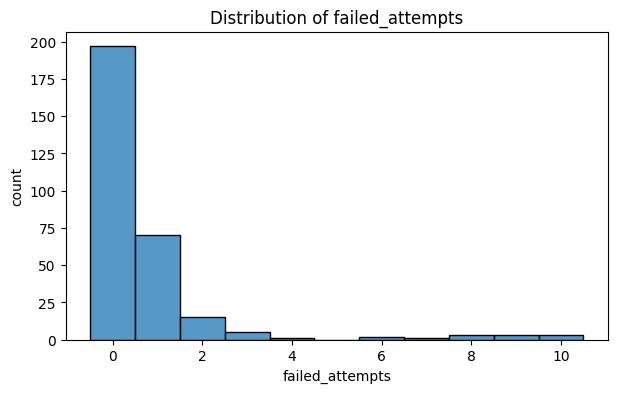

In [22]:
plt.figure(figsize=(7, 4))
sns.histplot(log["failed_attempts"], discrete=True)
plt.title("Distribution of failed_attempts")
plt.xlabel("failed_attempts")
plt.ylabel("count")
plt.show()


In [23]:
# Auto-graded cell - Skip it...

2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [24]:
answer_q2 = "B"
print(answer_q2)

B


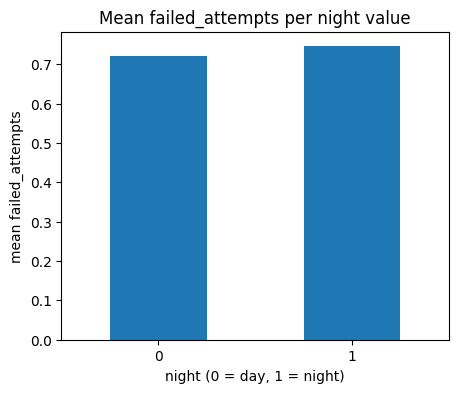

In [25]:
log["night"] = ((log["hour"] >= 22) | (log["hour"] < 6)).astype(int)

plt.figure(figsize=(5, 4))
log.groupby("night")["failed_attempts"].mean().plot(kind="bar")
plt.title("Mean failed_attempts per night value")
plt.xlabel("night (0 = day, 1 = night)")
plt.ylabel("mean failed_attempts")
plt.xticks(rotation=0)
plt.show()


In [26]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [27]:
# Please write a sentence response instead of code
# X[:, 2] returns the whole third column of X (all 300 rows, column index 2) as a 1-D array of shape (300,).

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [28]:
log.isna().sum()

,0
user,0
hour,0
failed_attempts,0
country,5
duration_min,5
long_session,0
night,0


Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

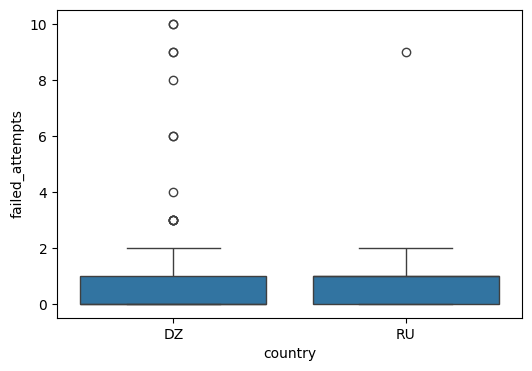

In [29]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="country", y="failed_attempts", data=log[log["country"].isin(["RU", "DZ"])])
plt.show()


Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [30]:
# Scaling puts all features on a comparable range so that no feature dominates the model just because of its units,
# and it helps gradient-based training converge faster.

Commit the logins_clean.csv.(0.5 point)

In [31]:
clean = log.copy()
clean["duration_min"] = clean["duration_min"].fillna(clean["duration_min"].median())
clean["country"] = clean["country"].fillna(clean["country"].mode()[0])
clean["long_session"] = (clean["duration_min"] > 30).astype(int)
assert clean.isna().sum().sum() == 0

clean.to_csv("logins_clean.csv", index=False)
clean.to_csv("login_clean.csv", index=False)
print(clean.shape)


(300, 7)


In [32]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [33]:
df = pd.read_csv("logins_clean.csv")
cols = ["hour", "failed_attempts", "duration_min", "night"]
X = df[cols].to_numpy(dtype=float)

X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
print(X_scaled.shape)


(300, 4)


In [34]:
import numpy as np
import pandas as pd
